# 11 — Estimação e Intervalos de Confiança

O notebook 10 mostrou que a média de uma amostra erra, em média, $\sigma / \sqrt{n}$. Agora vamos transformar isso em respostas práticas:
- Como julgar se uma fórmula é uma **boa** forma de estimar algo? (viés, variância e erro quadrático)
- Como dizer "a gorjeta média é de 16,1%, **mais ou menos quanto**"? (intervalos de confiança)
- E se a estatística for complicada (uma mediana, uma correlação, uma métrica de ML) e não houver fórmula? (o **bootstrap**)

Neste notebook vamos:
- Definir **estimador**, **viés**, **variância** e **erro quadrático médio** de um estimador
- Ver a **troca entre viés e variância** num exemplo simples
- Construir **intervalos de confiança** para a média, com a distribuição **t de Student**
- Verificar por simulação o que "95% de confiança" realmente significa
- Calcular intervalos para proporções
- Usar o **bootstrap** para a mediana e a correlação

## 1. Importando bibliotecas e carregando os dados

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.precision", 4)
plt.rcParams["figure.dpi"] = 100
rng = np.random.default_rng(42)

gorjetas = sns.load_dataset("tips")
gorjetas["percentual"] = gorjetas["tip"] / gorjetas["total_bill"] * 100

## 🎓 Conceito: estimador, viés e variância

- Um **parâmetro** é um número **fixo e desconhecido** da população (a média verdadeira $\mu$, por exemplo).
- Um **estimador** é uma **receita** para calcular, a partir da amostra, um palpite para o parâmetro (por exemplo, "a média da amostra"). O número que a receita produz numa amostra específica é a **estimativa**.

Como a amostra é aleatória, o estimador é uma **variável aleatória**, com a sua distribuição amostral (notebook 10). Para julgá-lo, olhamos:
- **Viés:** $E[\hat{\theta}] - \theta$. O estimador erra **sistematicamente** para um lado? (O $\hat{\theta}$, "teta chapéu", é o estimador do parâmetro $\theta$.)
- **Variância:** quanto o estimador oscila de amostra para amostra.
- **Erro quadrático médio (EQM):** o erro médio total, que junta os dois:
$$\text{EQM} = E[(\hat{\theta} - \theta)^2] = \text{viés}^2 + \text{variância}$$

Analogia: o **tiro ao alvo**. Viés é a mira desregulada (todos os tiros desviam para o mesmo lado); variância é a mão tremendo (os tiros se espalham). O que importa no fim é a **distância média até o centro**.

Já encontramos um caso no notebook 02: a variância dividida por $n$ é **viesada**, e dividir por $n-1$ corrige o viés.

In [2]:
# Três estimadores para o CENTRO de uma distribuição, testados em duas populações simétricas com centro 0:
#   - média, mediana e média "aparada" (descarta os 10% maiores e menores valores antes de tirar a média).
populacoes = {
    "Normal": lambda tamanho: rng.normal(0, 1, tamanho),
    "t de Student (caudas pesadas)": lambda tamanho: rng.standard_t(2, tamanho),
}
estimadores = {
    "média": lambda a: a.mean(axis=1),
    "mediana": lambda a: np.median(a, axis=1),
    "média aparada 10%": lambda a: stats.trim_mean(a, 0.1, axis=1),
}

linhas = []
for nome_pop, sortear in populacoes.items():
    amostras = sortear((20_000, 25))           # 20.000 amostras de 25 valores
    for nome_est, estimar in estimadores.items():
        est = estimar(amostras)
        linhas.append({"população": nome_pop, "estimador": nome_est,
                       "viés": est.mean(), "variância": est.var(), "EQM": np.mean(est ** 2)})   # o valor verdadeiro é 0
pd.DataFrame(linhas).set_index(["população", "estimador"])

viés  variância     EQM
população                     estimador                                   
Normal                        média             -0.0005     0.0401  0.0401
                              mediana           -0.0013     0.0612  0.0612
                              média aparada 10% -0.0006     0.0417  0.0417
t de Student (caudas pesadas) média              0.0024     2.3741  2.3741
                              mediana            0.0033     0.0814  0.0814
                              média aparada 10%  0.0044     0.0951  0.0951

**Conclusão:** os três estimadores praticamente **não têm viés** nas duas populações (todos os vieses ficam abaixo de 0,005), já que ambas são simétricas em torno de 0. A diferença está na **variância**:
- Na **normal**, a média é a melhor (EQM **0,040**), a média aparada fica quase igual (0,042) e a mediana é a pior (**0,061**, cerca de 50% a mais).
- Na **t de Student com caudas pesadas**, a situação se inverte: a média é péssima (EQM **2,37**), porque um único valor extremo arrasta a média da amostra inteira. A mediana (**0,081**) e a média aparada (0,095) são cerca de **25 a 30 vezes** melhores.

Não existe um estimador melhor em todas as situações. A média é ótima com dados "bem comportados", e os estimadores **robustos** protegem contra caudas pesadas, pagando um preço pequeno quando os dados são normais.

## 🎓 Conceito: a troca entre viés e variância

Um estimador **sem viés** nem sempre é o melhor. Às vezes, aceitar um **pouco de viés** em troca de **muito menos variância** diminui o erro total.

Exemplo: queremos estimar uma média $\mu$ com uma amostra pequena. Em vez da média $\bar{x}$, usamos um estimador "encolhido" em direção ao zero: $c \cdot \bar{x}$, com $0 < c < 1$. Encolher introduz viés (ele subestima $\mu$), mas reduz a variância por um fator $c^2$.

🔗 **Ponte para o ML:** é exatamente o que faz a **regularização** (Ridge e Lasso, no notebook 09 do ML-01): os coeficientes são "encolhidos" em direção a zero, ganhando viés e perdendo variância. E é a mesma troca entre **underfitting** (muito viés) e **overfitting** (muita variância). No notebook 16 vamos ver que esse encolhimento tem uma interpretação bayesiana.

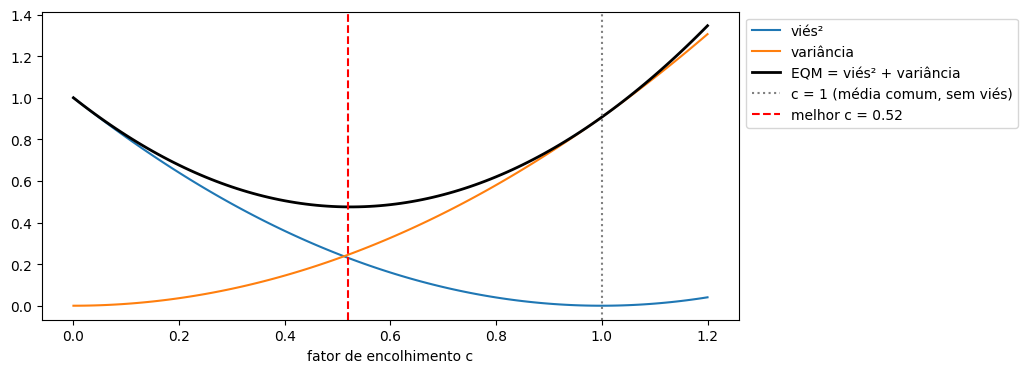

EQM da média comum (c = 1):     0.9069
EQM do melhor encolhimento:     0.4752  (c = 0.52)
c ótimo pela teoria:            0.53


In [3]:
mu_verdadeira, sigma, n = 1.0, 3.0, 10
amostras = rng.normal(mu_verdadeira, sigma, size=(50_000, n))
medias = amostras.mean(axis=1)

fatores = np.linspace(0, 1.2, 121)
vies2 = [(np.mean(c * medias) - mu_verdadeira) ** 2 for c in fatores]
variancia = [np.var(c * medias) for c in fatores]
eqm = [np.mean((c * medias - mu_verdadeira) ** 2) for c in fatores]
melhor = fatores[np.argmin(eqm)]

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(fatores, vies2, label="viés²")
ax.plot(fatores, variancia, label="variância")
ax.plot(fatores, eqm, color="black", linewidth=2, label="EQM = viés² + variância")
ax.axvline(1, color="gray", linestyle=":", label="c = 1 (média comum, sem viés)")
ax.axvline(melhor, color="red", linestyle="--", label=f"melhor c = {melhor:.2f}")
ax.set_xlabel("fator de encolhimento c")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"EQM da média comum (c = 1):     {eqm[np.argmin(np.abs(fatores - 1))]:.4f}")
print(f"EQM do melhor encolhimento:     {min(eqm):.4f}  (c = {melhor:.2f})")
# A teoria diz que o melhor c é μ² / (μ² + σ²/n).
print(f"c ótimo pela teoria:            {mu_verdadeira**2 / (mu_verdadeira**2 + sigma**2 / n):.2f}")

**Conclusão:** com $\mu = 1$, $\sigma = 3$ e só 10 valores, a média comum (c = 1, sem viés) tem EQM de **0,907**, quase todo de variância. Encolher a média pela metade (**c = 0,52**) cria viés, mas corta tanto a variância que o EQM cai para **0,475**, quase a metade. O melhor c da simulação bate com a teoria (**0,53**).

No gráfico, o viés² (azul) cresce quando encolhemos mais e a variância (laranja) cresce quando encolhemos menos; o EQM (preto) tem o seu mínimo onde as duas se equilibram. É o mesmo formato de "U" da curva de complexidade do ML-01.

Um detalhe importante: o c ótimo depende do $\mu$ **verdadeiro**, que não conhecemos. Na prática, a força do encolhimento é escolhida com os dados, por exemplo com **validação cruzada**, como fizemos com o `alpha` do Ridge no ML-01.

## 🎓 Conceito: intervalo de confiança

Uma estimativa isolada ("a gorjeta média é 16,1%") não diz nada sobre a sua precisão. Um **intervalo de confiança** (IC) dá uma **faixa de valores plausíveis** para o parâmetro.

Pelo TCL, a média da amostra fica a menos de $1{,}96$ erros padrão de $\mu$ em 95% das amostras. Invertendo o raciocínio, o intervalo

$$\bar{x} \pm 1{,}96 \cdot \frac{\sigma}{\sqrt{n}}$$

contém $\mu$ em 95% das amostras. Esse é o **IC de 95%**.

**O que "95% de confiança" significa (e o que não significa):** o parâmetro $\mu$ é **fixo**; o que é aleatório é o **intervalo**, que muda de amostra para amostra. "95%" é a taxa de acerto do **método**: se repetíssemos o estudo muitas vezes, 95% dos intervalos construídos assim conteriam $\mu$. Para um intervalo específico, já calculado, ele contém ou não contém $\mu$; não sabemos qual dos dois.

## 🎓 Conceito: a distribuição t de Student

Na prática, **não conhecemos** $\sigma$ e usamos o desvio da amostra $s$ no lugar. Isso acrescenta incerteza: com amostras pequenas, $s$ pode sair bem menor que $\sigma$ e deixar o intervalo estreito demais.

O estatístico William Gosset (que trabalhava na cervejaria Guinness e publicava sob o pseudônimo "Student") descobriu a correção: com $s$ no lugar de $\sigma$, a quantidade $\frac{\bar{X} - \mu}{s / \sqrt{n}}$ não segue uma normal, e sim uma **t de Student** com $n - 1$ graus de liberdade. Ela parece uma normal com **caudas mais pesadas**, e se aproxima da normal quando $n$ cresce. O IC passa a ser:

$$\bar{x} \pm t_{n-1;\,0{,}975} \cdot \frac{s}{\sqrt{n}}$$

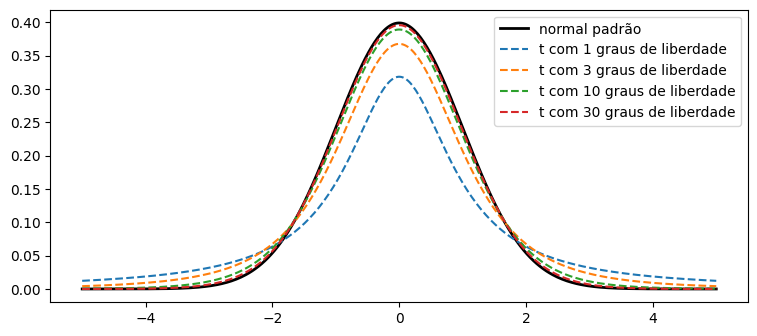

n =    3: t(0,975;   2 gl) = 4.303   (normal: 1,960)
n =    5: t(0,975;   4 gl) = 2.776   (normal: 1,960)
n =   10: t(0,975;   9 gl) = 2.262   (normal: 1,960)
n =   30: t(0,975;  29 gl) = 2.045   (normal: 1,960)
n =  100: t(0,975;  99 gl) = 1.984   (normal: 1,960)
n = 1000: t(0,975; 999 gl) = 1.962   (normal: 1,960)


In [4]:
fig, ax = plt.subplots(figsize=(9, 3.8))
eixo = np.linspace(-5, 5, 400)
ax.plot(eixo, stats.norm.pdf(eixo), color="black", linewidth=2, label="normal padrão")
for gl in [1, 3, 10, 30]:
    ax.plot(eixo, stats.t.pdf(eixo, df=gl), linestyle="--", label=f"t com {gl} graus de liberdade")
ax.legend()
plt.show()

# O multiplicador do IC de 95% para cada tamanho de amostra.
for n_i in [3, 5, 10, 30, 100, 1000]:
    print(f"n = {n_i:>4}: t(0,975; {n_i - 1:>3} gl) = {stats.t.ppf(0.975, df=n_i - 1):.3f}   (normal: 1,960)")

**Conclusão:** a t com 1 grau de liberdade tem caudas **muito** mais pesadas que a normal; com 10 graus já fica parecida, e com 30 é quase indistinguível. O multiplicador do IC reflete isso: com $n = 3$ ele é **4,303**, mais que o dobro de 1,96; com $n = 10$, 2,262; com $n = 30$, 2,045; e com $n = 1.000$, **1,962**, praticamente o da normal. Com amostras pequenas, a t "alarga" o intervalo para compensar a incerteza extra de estimar $\sigma$.

## 2. Verificando a cobertura por simulação

Vamos testar o método: sortear muitas amostras de uma população com $\mu$ conhecida, construir um IC de 95% para cada uma e contar quantos contêm $\mu$. Faremos isso com o multiplicador correto (t) e com o da normal (1,96), usando amostras pequenas.

     cobertura com 1,96  cobertura com t
n                                       
3                0.8121           0.9529
5                0.8772           0.9503
10               0.9186           0.9509
30               0.9414           0.9474
100              0.9454           0.9500


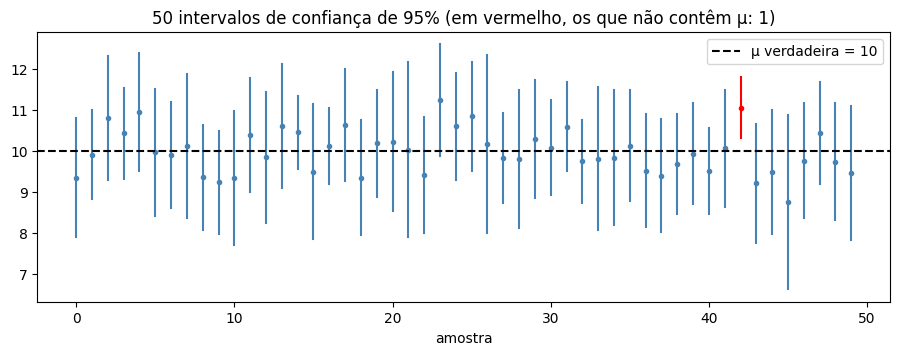

In [5]:
def cobertura(n, multiplicador, repeticoes=20_000, mu=10, sigma=2):
    """Proporção de ICs  x̄ ± multiplicador·s/√n  que contêm a média verdadeira."""
    amostras = rng.normal(mu, sigma, size=(repeticoes, n))
    medias = amostras.mean(axis=1)
    ep = amostras.std(axis=1, ddof=1) / np.sqrt(n)
    return np.mean((medias - multiplicador * ep <= mu) & (mu <= medias + multiplicador * ep))


linhas = [{"n": n_i,
           "cobertura com 1,96": cobertura(n_i, 1.96),
           "cobertura com t": cobertura(n_i, stats.t.ppf(0.975, n_i - 1))} for n_i in [3, 5, 10, 30, 100]]
print(pd.DataFrame(linhas).set_index("n"))

# Desenhando 50 intervalos (n = 10): em vermelho, os que NÃO contêm μ = 10.
amostras = rng.normal(10, 2, size=(50, 10))
medias = amostras.mean(axis=1)
margem = stats.t.ppf(0.975, 9) * amostras.std(axis=1, ddof=1) / np.sqrt(10)
erraram = (medias - margem > 10) | (medias + margem < 10)

fig, ax = plt.subplots(figsize=(11, 3.5))
for i in range(50):
    ax.plot([i, i], [medias[i] - margem[i], medias[i] + margem[i]], color="red" if erraram[i] else "steelblue")   # "if/else" numa linha só
    ax.plot(i, medias[i], "o", color="red" if erraram[i] else "steelblue", markersize=3)
ax.axhline(10, color="black", linestyle="--", label="μ verdadeira = 10")
ax.set_xlabel("amostra")
ax.set_title(f"50 intervalos de confiança de 95% (em vermelho, os que não contêm μ: {erraram.sum()})")
ax.legend()
plt.show()

**Conclusão:** com o multiplicador da **t**, a cobertura fica em **95%** em todos os tamanhos de amostra (de 94,7% a 95,3%), exatamente o prometido. Com **1,96**, os intervalos ficam estreitos demais em amostras pequenas: com $n = 3$, só **81,2%** contêm $\mu$; com $n = 10$, 91,9%. A diferença só desaparece por volta de $n = 100$ (94,5%).

No gráfico, dos 50 intervalos com $n = 10$, **1** não contém $\mu$ (em vermelho), perto dos 2 ou 3 que esperaríamos (5% de 50). Repare que cada intervalo tem uma largura diferente, porque o desvio $s$ também muda de amostra para amostra.

## 3. Intervalos de confiança com os dados do tips

Percentual médio de gorjeta: 16.08%   IC 95%: [15.31%, 16.85%]
scipy: [15.31 16.85]
       n    média  IC inferior  IC superior  largura
dia                                                 
Thur  62  16.1276      15.1460      17.1091   1.9631
Fri   19  16.9913      14.6939      19.2887   4.5948
Sat   87  15.3152      14.2220      16.4084   2.1864
Sun   76  16.6897      14.7534      18.6261   3.8727


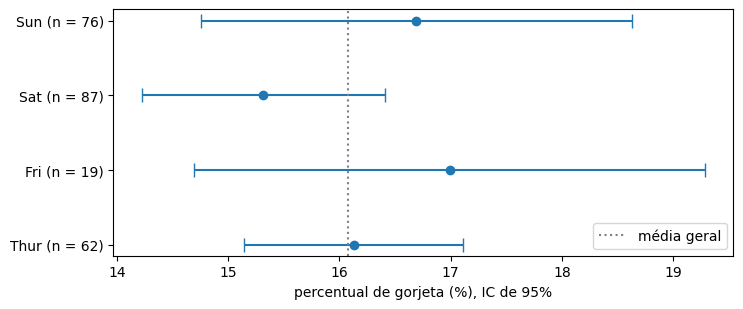

In [6]:
def ic_media(valores, confianca=0.95):
    """IC para a média com a distribuição t. Devolve (média, limite inferior, limite superior)."""
    n = len(valores)
    media = np.mean(valores)
    ep = np.std(valores, ddof=1) / np.sqrt(n)
    t = stats.t.ppf((1 + confianca) / 2, df=n - 1)
    return media, media - t * ep, media + t * ep


media, inf, sup = ic_media(gorjetas["percentual"])
print(f"Percentual médio de gorjeta: {media:.2f}%   IC 95%: [{inf:.2f}%, {sup:.2f}%]")
# O scipy faz a mesma conta: stats.t.interval(confiança, gl, loc=média, scale=erro padrão).
print("scipy:", np.round(stats.t.interval(0.95, len(gorjetas) - 1, loc=media, scale=stats.sem(gorjetas["percentual"])), 2))

# Um IC por dia da semana.
linhas = []
for dia, grupo in gorjetas.groupby("day", observed=True):
    m, i, s = ic_media(grupo["percentual"])
    linhas.append({"dia": dia, "n": len(grupo), "média": m, "IC inferior": i, "IC superior": s, "largura": s - i})
por_dia = pd.DataFrame(linhas).set_index("dia")
print(por_dia)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(por_dia["média"], range(len(por_dia)),   # errorbar desenha um ponto com uma barra de erro
            xerr=[por_dia["média"] - por_dia["IC inferior"], por_dia["IC superior"] - por_dia["média"]],
            fmt="o", capsize=5)
ax.set_yticks(range(len(por_dia)))
ax.set_yticklabels([f"{d} (n = {n})" for d, n in zip(por_dia.index, por_dia["n"])])
ax.axvline(media, color="gray", linestyle=":", label="média geral")
ax.set_xlabel("percentual de gorjeta (%), IC de 95%")
ax.legend()
plt.show()

**Conclusão:** o percentual médio de gorjeta é **16,08%**, com IC de 95% de **[15,31%, 16,85%]**: considerando a incerteza da amostra, a média verdadeira desse restaurante é plausivelmente qualquer valor entre cerca de 15,3% e 16,9%. O cálculo à mão bate com o do scipy.

Por dia, a **largura** dos intervalos conta muito: a sexta, com só **19 mesas**, tem o intervalo mais largo (**4,6 pontos**, de 14,7% a 19,3%), e a quinta, com 62 mesas, um dos mais estreitos (2,0 pontos). O domingo tem intervalo largo (3,9 pontos) mesmo com 76 mesas: a culpa é do desvio alto causado pela mesa de 71%. Todos os intervalos **se sobrepõem bastante** e incluem a média geral, então os dados não dão sinais fortes de que algum dia seja diferente.

## 🎓 Conceito: intervalo de confiança para uma proporção

Uma proporção $\hat{p}$ é a média de zeros e uns, então o TCL também vale. Pelo notebook 10, o erro padrão é $\sqrt{p(1-p)/n}$, e usamos $\hat{p}$ no lugar do $p$ desconhecido:

$$\hat{p} \pm 1{,}96 \sqrt{\frac{\hat{p}(1-\hat{p})}{n}}$$

Esse é o **intervalo de Wald**, o mais simples. Ele funciona mal quando $n$ é pequeno ou $\hat{p}$ está perto de 0 ou 1. Uma alternativa melhor, e quase tão simples, é o **intervalo de Wilson**, que o `statsmodels` calcula para nós.

In [7]:
from statsmodels.stats.proportion import proportion_confint   # importar no meio do notebook também funciona

for rotulo, grupo in [("todas as mesas", gorjetas), ("só sexta-feira", gorjetas[gorjetas["day"] == "Fri"])]:
    sucessos = (grupo["smoker"] == "Yes").sum()
    n = len(grupo)
    wald = proportion_confint(sucessos, n, alpha=0.05, method="normal")
    wilson = proportion_confint(sucessos, n, alpha=0.05, method="wilson")
    print(f"{rotulo:>15}: {sucessos}/{n} = {sucessos / n:.1%} fumantes   "
          f"Wald: [{wald[0]:.1%}, {wald[1]:.1%}]   Wilson: [{wilson[0]:.1%}, {wilson[1]:.1%}]")

 todas as mesas: 93/244 = 38.1% fumantes   Wald: [32.0%, 44.2%]   Wilson: [32.2%, 44.3%]
 só sexta-feira: 15/19 = 78.9% fumantes   Wald: [60.6%, 97.3%]   Wilson: [56.7%, 91.5%]


**Conclusão:** para todas as mesas, os dois métodos praticamente concordam: **38,1%** de fumantes, com IC de cerca de **32% a 44%**. Na sexta-feira, com apenas 19 mesas e uma proporção alta (78,9%), eles divergem: o intervalo de Wald vai até **97,3%** e é simétrico, ignorando que a proporção não pode passar de 100%; o de Wilson, **[56,7%, 91,5%]**, é assimétrico e mais confiável nesses casos.

De todo modo, mesmo o limite **inferior** da sexta (56,7%) fica acima do limite **superior** geral (44,3%), um forte indício de que a sexta realmente tem mais mesas com fumantes. O notebook 12 vai testar isso formalmente.

## 🎓 Conceito: bootstrap

E se quisermos um IC para a **mediana**? Ou para uma **correlação**? Ou para a AUC de um modelo? Não há uma fórmula simples como $\sigma/\sqrt{n}$ para tudo.

O **bootstrap** (Bradley Efron, 1979) resolve com uma ideia engenhosa: a amostra é a nossa melhor imagem da população. Então, **simulamos novas amostras sorteando da própria amostra, com reposição**:
1. Sorteie $n$ valores da amostra **com reposição** (o mesmo valor pode sair várias vezes, e outros não saem). Isso é uma **amostra bootstrap**.
2. Calcule a estatística (a mediana, por exemplo) nessa amostra.
3. Repita milhares de vezes. A distribuição das estatísticas imita a **distribuição amostral**.
4. O IC de 95% é a faixa entre os percentis 2,5 e 97,5 dessas estatísticas (o **IC percentil**).

O nome vem da expressão "levantar-se puxando os cordões das próprias botas" (*pull oneself up by one's bootstraps*): estimamos a incerteza usando apenas os dados que temos.

🔗 **Ponte para o ML:** o **bagging** (e a random forest) treina cada árvore numa amostra bootstrap dos dados, exatamente este sorteio com reposição.

Uma amostra bootstrap repete valores: 158 mesas diferentes de 244
Mediana: 17.80   IC 95% bootstrap: [16.53, 18.68]
Média:   19.79   IC 95% bootstrap: [18.69, 20.93]   pela fórmula t: [18.66, 20.91]
Erro padrão da média — bootstrap: 0.572   fórmula s/√n: 0.570


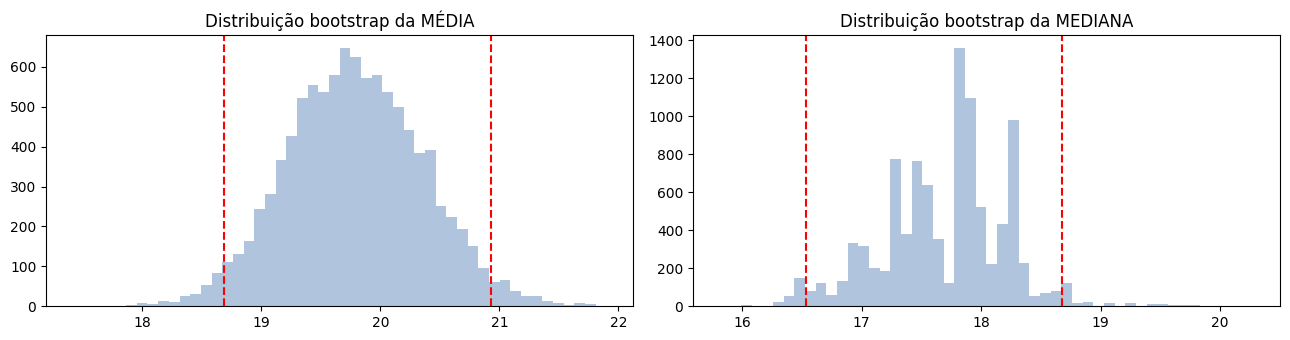

In [8]:
contas = gorjetas["total_bill"].to_numpy()

# Bootstrap à mão para a mediana.
n_boot = 10_000
# Cada linha de "indices" é uma amostra bootstrap: n posições sorteadas com reposição.
indices = rng.integers(0, len(contas), size=(n_boot, len(contas)))
medianas_boot = np.median(contas[indices], axis=1)
ic_mediana = np.percentile(medianas_boot, [2.5, 97.5])   # percentile usa porcentagens (0 a 100)

# Conferindo o método na MÉDIA, onde conhecemos a resposta pela fórmula t.
medias_boot = contas[indices].mean(axis=1)
_, t_inf, t_sup = ic_media(contas)

print(f"Uma amostra bootstrap repete valores: {len(np.unique(indices[0]))} mesas diferentes de {len(contas)}")
print(f"Mediana: {np.median(contas):.2f}   IC 95% bootstrap: [{ic_mediana[0]:.2f}, {ic_mediana[1]:.2f}]")
print(f"Média:   {contas.mean():.2f}   IC 95% bootstrap: [{np.percentile(medias_boot, 2.5):.2f}, {np.percentile(medias_boot, 97.5):.2f}]"
      f"   pela fórmula t: [{t_inf:.2f}, {t_sup:.2f}]")
print(f"Erro padrão da média — bootstrap: {medias_boot.std():.3f}   fórmula s/√n: {stats.sem(contas):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.5))
axes[0].hist(medias_boot, bins=50, color="lightsteelblue")
axes[0].set_title("Distribuição bootstrap da MÉDIA")
axes[1].hist(medianas_boot, bins=50, color="lightsteelblue")
axes[1].set_title("Distribuição bootstrap da MEDIANA")
for ax, ic in zip(axes, [np.percentile(medias_boot, [2.5, 97.5]), ic_mediana]):
    for limite in ic:
        ax.axvline(limite, color="red", linestyle="--")
plt.tight_layout()
plt.show()

In [9]:
# O scipy tem o bootstrap pronto, com um método mais refinado (BCa) que corrige viés e assimetria.
conta = gorjetas["total_bill"].to_numpy()
gorjeta = gorjetas["tip"].to_numpy()

def correlacao(x, y):
    return np.corrcoef(x, y)[0, 1]

# paired=True: sorteia as MESAS (pares conta-gorjeta), mantendo cada conta junto da sua gorjeta.
resultado = stats.bootstrap((conta, gorjeta), correlacao, paired=True, vectorized=False,
                            n_resamples=5_000, confidence_level=0.95, method="BCa", random_state=rng)
ic = resultado.confidence_interval
print(f"Correlação conta × gorjeta: {correlacao(conta, gorjeta):.3f}   IC 95% (bootstrap BCa): [{ic.low:.3f}, {ic.high:.3f}]")

Correlação conta × gorjeta: 0.676   IC 95% (bootstrap BCa): [0.566, 0.762]


**Conclusão:** cada amostra bootstrap contém só **158** das 244 mesas diferentes (as outras são repetições), e mesmo assim o método funciona:
- Para a **média**, o IC bootstrap **[18,69; 20,93]** é quase idêntico ao da fórmula t **[18,66; 20,91]**, e o erro padrão bootstrap (**0,572**) bate com $s/\sqrt{n}$ (0,570). O bootstrap passa no teste em que conhecemos a resposta.
- Para a **mediana**, sem fórmula simples, ele dá **[16,53; 18,68]**. A distribuição bootstrap da mediana é "dentada" (direita), porque a mediana só pode assumir valores (ou médias de pares de valores) que existem nos dados.
- Para a **correlação** conta × gorjeta (0,676), o IC BCa é **[0,566; 0,762]**: assimétrico em torno de 0,676, porque a correlação é limitada a 1. Mesmo no limite inferior, a relação continua moderada a forte.

## 4. Resumo e próximos passos

| Situação | Intervalo de confiança |
|---|---|
| média, $\sigma$ desconhecido | $\bar{x} \pm t_{n-1;\,0{,}975} \cdot s/\sqrt{n}$ |
| proporção | Wilson (ou Wald, com $n$ grande e $\hat{p}$ longe de 0 e 1) |
| qualquer outra estatística | bootstrap (percentil ou BCa) |

**Conceitos que você aprendeu**
- **Estimador, estimativa e parâmetro**; **viés, variância e EQM** = viés² + variância.
- Estimadores **robustos** (mediana, média aparada) ganham da média quando há caudas pesadas.
- A **troca entre viés e variância** com um estimador encolhido (a ideia da regularização).
- **Intervalos de confiança**, a interpretação correta de "95%" e a **distribuição t**.
- ICs para **proporções** (Wald e Wilson).
- O **bootstrap** para a mediana e a correlação, e a sua ligação com o bagging.

🔗 **Ponte para o ML:** uma pontuação de validação cruzada também merece um intervalo. Com 5 dobras, podemos usar $\bar{x} \pm t_{4;\,0{,}975} \cdot s/\sqrt{5}$ (com a ressalva de que as dobras não são totalmente independentes, porque compartilham dados de treino), ou o bootstrap das previsões no conjunto de teste para obter um IC da métrica final.

**Python novo:** `stats.trim_mean`, `stats.t` (`.pdf`, `.ppf`, `.interval`), `stats.sem`, `ax.errorbar`, `set_yticklabels`, `proportion_confint` do statsmodels, `np.percentile`, `np.unique`, `stats.bootstrap`, `if/else` numa linha.

**Próximo notebook:** os ICs por dia da semana se sobrepunham bastante. Mas como decidir, de forma objetiva, se uma diferença entre grupos é **real** ou **acaso**? No notebook 12 vamos aos **testes de hipótese**: p-valor, erros tipo I e II, poder, teste t, qui-quadrado, testes de permutação e o perigo dos **testes múltiplos**.